In [1]:
import astropy.coordinates as coord
import astropy.table as at
import astropy.units as u
import gala.coordinates as gc
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from astropy.constants import c
from pyia import GaiaData

%matplotlib inline

In [2]:
import arviz as az
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
import numpyro.infer as infer

numpyro.enable_x64()
numpyro.set_host_device_count(4)
jax.local_device_count()

4

interim membership probabilities shared by Kiyan

In [141]:
g = GaiaData("../data/gd1_memb_prob_all.fits")

In [142]:
prob_mask = g.data["memb_prob"] >= 0.0
prob_mask_75 = g.data["memb_prob"] >= 0.75
prob_mask.sum(), prob_mask_75.sum()

(np.int64(521925), np.int64(14205))

In [5]:
len(g)

521925

In [6]:
members = g[prob_mask]
members_c = members.get_skycoord(distance=False)

In [7]:
members_c_str = members_c.transform_to(gc.GD1Koposov10())

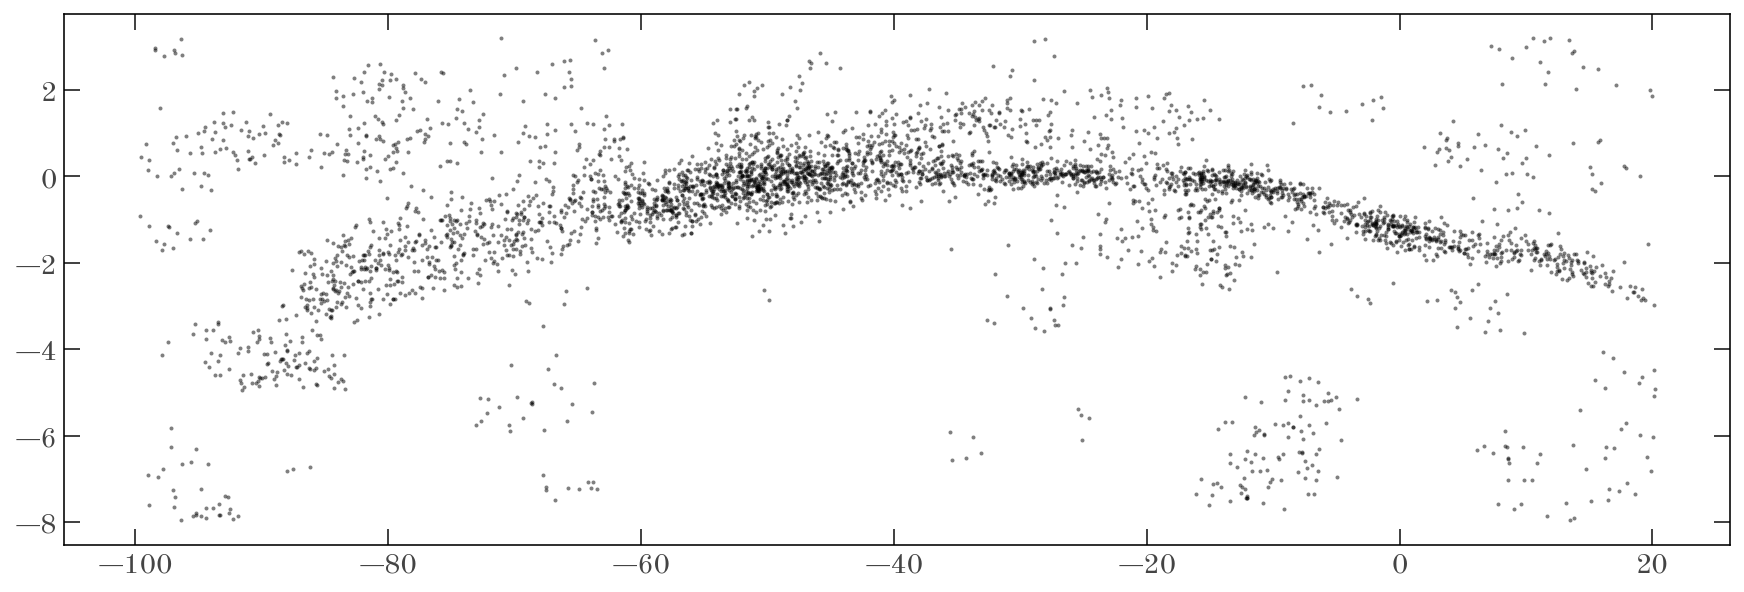

In [8]:
prob_mask_strict = members.memb_prob > 0.99
plt.figure(figsize=(12, 4))
plt.plot(
    members_c_str.phi1.degree[prob_mask_strict],
    members_c_str.phi2.degree[prob_mask_strict],
    marker="o",
    mew=0,
    ms=2.0,
    alpha=0.5,
    ls="none",
);

# Gaia

I had to xmatch to get RV data:

In [9]:
tbl2 = at.Table.read("../data/gaia-rv-xm.fits.gz")
tbl2 = tbl2[~tbl2["radial_velocity"].mask]
gaia_g = GaiaData(at.join(members.data, tbl2, keys="source_id"))
len(gaia_g)

16610

# Hectospec

In [10]:
hecto = at.Table.read("~/projects/gd1-dr3/data/hecto-catalog.fits")
hecto_xm = at.join(hecto, members.data["source_id", "memb_prob"])

hecto_g = GaiaData(
    hecto_xm,
    radial_velocity_colname="Vrad",
    radial_velocity_error_colname="std_Vrad",
    radial_velocity_unit=u.km / u.s,
)

len(hecto), len(hecto_g)

(1160, 688)

# APOGEE

In [11]:
tmp1 = at.Table.read("~/data/APOGEE/DR17/allStarLite-dr17-synspec_rev1.fits")
tmp2 = at.Table.read(
    "~/data/APOGEE/DR17/allStar-dr17-synspec-gaiadr3-gaiasourcelite.fits"
)
apogee = at.join(tmp1, tmp2, keys_left="APOGEE_ID", keys_right="apogee_id")

In [12]:
apogee_xm = at.join(
    apogee,
    members.data,
    keys="source_id",
    uniq_col_name="{col_name}{table_name}",
    table_names=["_apogee", ""],
)
apogee_g = GaiaData(
    apogee_xm,
    radial_velocity_colname="VHELIO_AVG",
    radial_velocity_error_colname="VERR",
    radial_velocity_unit=u.km / u.s,
)
len(apogee_g)

1339

# SDSS

In [102]:
sspp = at.Table.read("~/data/SDSSI-IV/SEGUE/ssppOut-dr12.fits")
sspp["SPECOBJID"] = [s.strip() for s in sspp["SPECOBJID"].astype(str)]

In [ ]:
sdss = at.Table.read("~/data/SDSSI-IV/specObjAll-STAR.fits")
sdss["SPECOBJID"] = [s.strip() for s in sdss["specObjID"].astype(str)]
sdss["rv"] = c.to(u.km / u.s) * sdss["z"] + 7.55 * u.km / u.s
sdss["rv_err"] = c.to(u.km / u.s) * sdss["zErr"]

sdss = at.join(sdss, sspp, keys="SPECOBJID", join_type="left")

In [105]:
sdss_c = coord.SkyCoord(sdss["ra"] * u.deg, sdss["dec"] * u.deg)

In [106]:
idx, sep, _ = coord.match_coordinates_sky(sdss_c, members_c)

sep_mask = sep < 4 * u.arcsec

sdss_xm = at.hstack(
    (sdss[sep_mask], members.data[idx[sep_mask]]),
    uniq_col_name="{col_name}{table_name}",
    table_names=["_sdss", ""],
)

sdss_g = GaiaData(
    sdss_xm, radial_velocity_colname="rv", radial_velocity_error_colname="rv_err"
)
len(sdss_g)

16175

# DESI

In [16]:
desi = at.Table.read("~/data/DESI/EDR/mwsall-pix-fuji.fits")

In [17]:
desi_c = coord.SkyCoord(desi["TARGET_RA"] * u.deg, desi["TARGET_DEC"] * u.deg)

In [18]:
idx, sep, _ = coord.match_coordinates_sky(desi_c, members_c)

sep_mask = sep < 4 * u.arcsec

desi_xm = at.hstack(
    (desi[sep_mask], members.data[idx[sep_mask]]),
    uniq_col_name="{col_name}{table_name}",
    table_names=["_desi", ""],
)

desi_g = GaiaData(
    desi_xm,
    radial_velocity_colname="VRAD",
    radial_velocity_error_colname="VRAD_ERR",
    radial_velocity_unit=u.km / u.s,
)
len(desi_g)

7808

Compare SDSS and DESI

In [19]:
idx, sep, _ = coord.match_coordinates_sky(desi_c, sdss_c)
sep_mask = sep < 2 * u.arcsec

drv = desi["VRAD"][sep_mask] - sdss["rv"].value[idx[sep_mask]]
np.mean(drv), np.median(drv)

(np.float64(-0.6956721122570179), np.float64(-0.01645388869389741))

# Ibata

TODO: Data not public

https://ui.adsabs.harvard.edu/abs/2020ApJ...891..161I/abstract

---

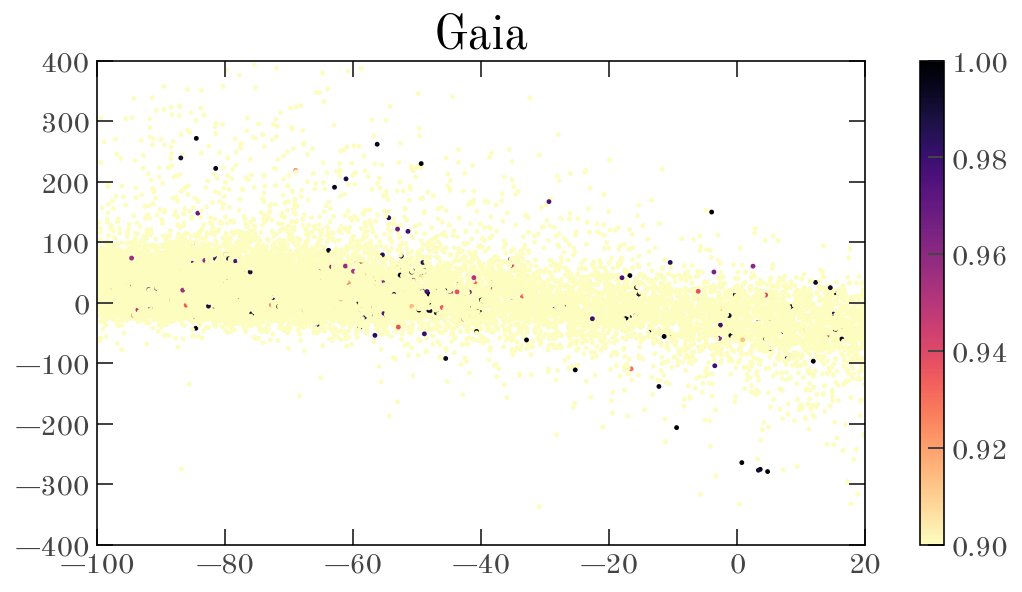

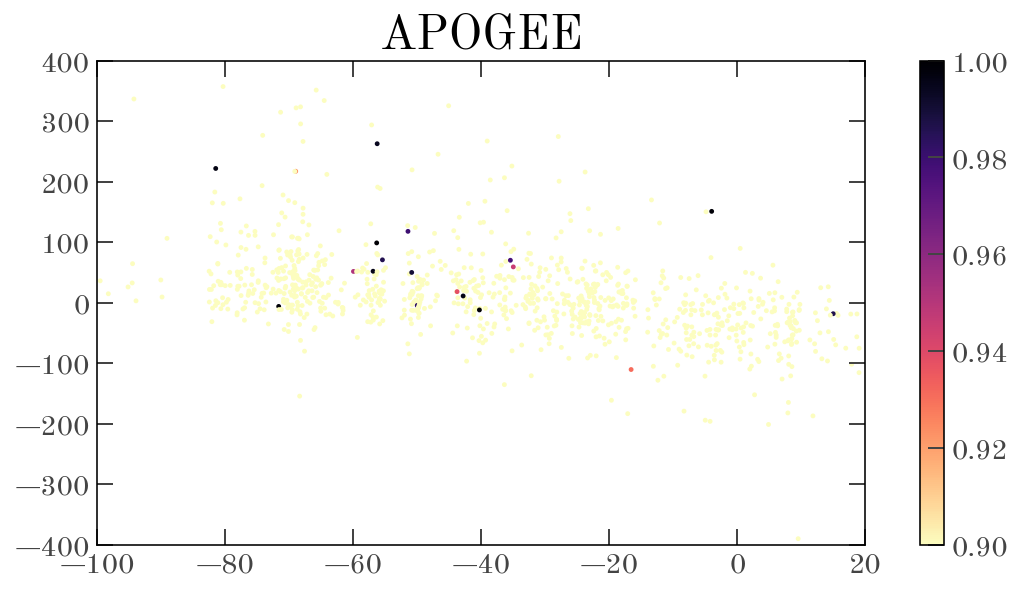

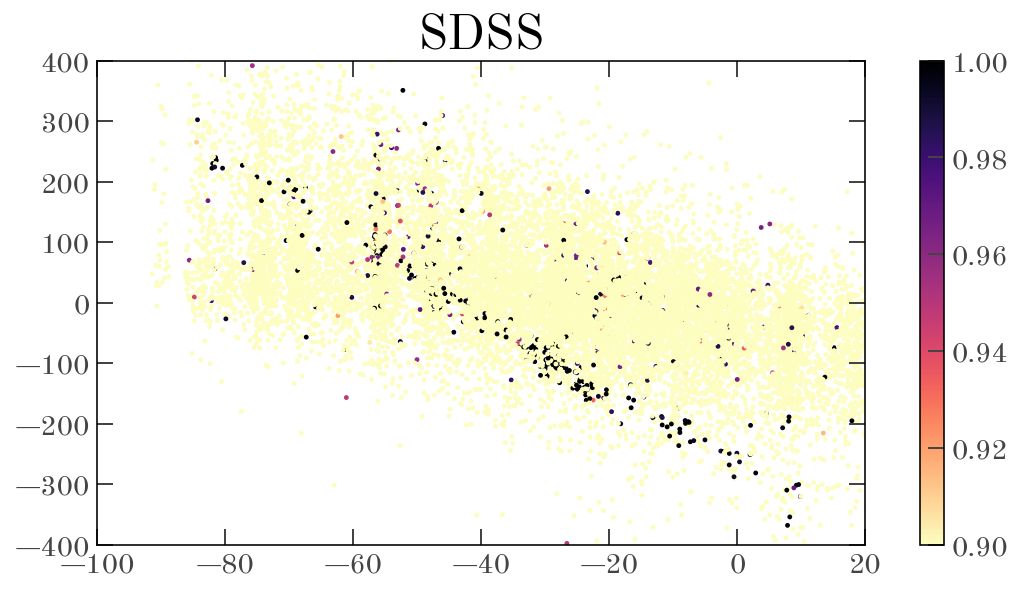

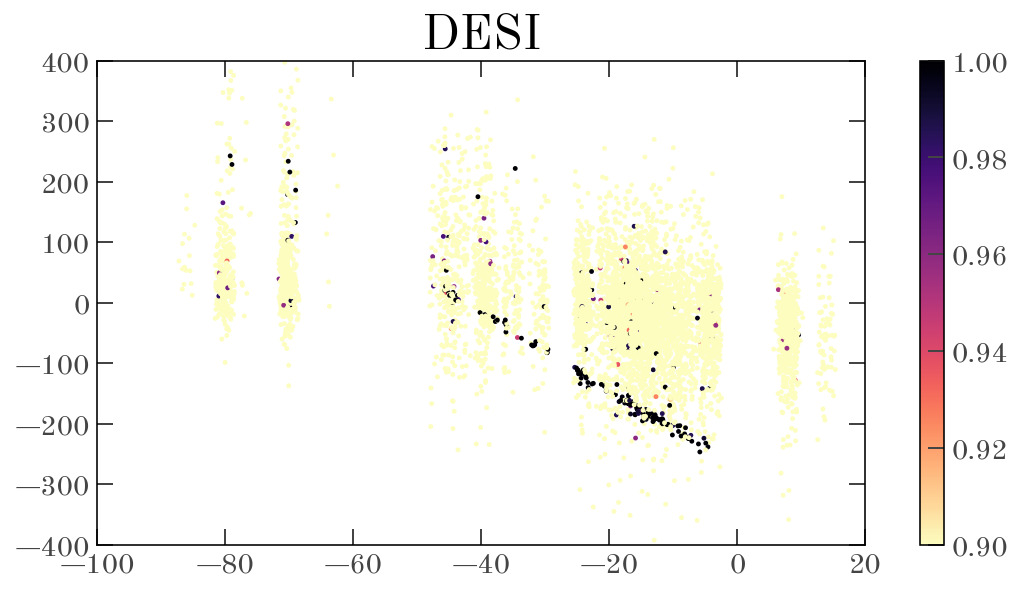

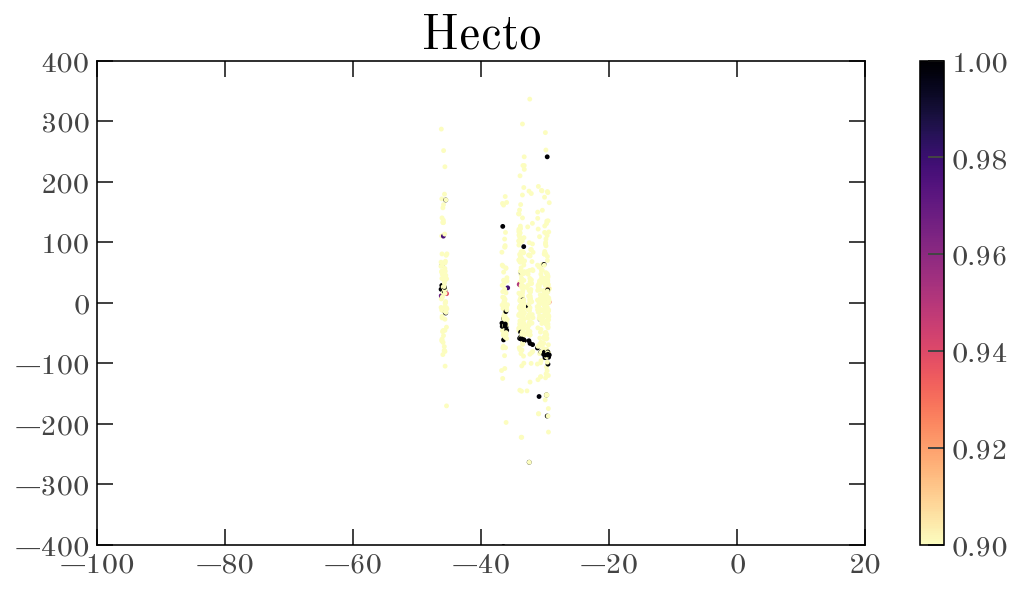

In [108]:
all_spec = [gaia_g, apogee_g, sdss_g, desi_g, hecto_g]
all_spec = [s[np.isfinite(s.get_radial_velocity())] for s in all_spec]
all_spec = [s[np.unique(s.source_id, return_index=True)[1]] for s in all_spec]
names = ["Gaia", "APOGEE", "SDSS", "DESI", "Hecto"]
all_spec = {k: s for k, s in zip(names, all_spec)}

for name, spec in all_spec.items():
    tmp_c = spec.get_skycoord(distance=10 * u.kpc)
    tmp_c = tmp_c.transform_to(gc.GD1Koposov10())
    # tmp_c = gc.reflex_correct(tmp_c)

    plt.figure(figsize=(7, 4))
    plt.title(name)
    plt.scatter(
        tmp_c.phi1.degree,
        tmp_c.radial_velocity.to_value(u.km / u.s),
        c=spec.memb_prob,
        s=2,
        cmap="magma_r",
        vmin=0.9,
        vmax=1.0,
    )
    plt.xlim(-100, 20)
    plt.ylim(-400, 400)
    plt.colorbar()

    # plt.scatter(-80, 225, marker='s', color='c', s=100)
    # plt.scatter(10, -320, marker='s', color='c', s=100)

# plt.legend()

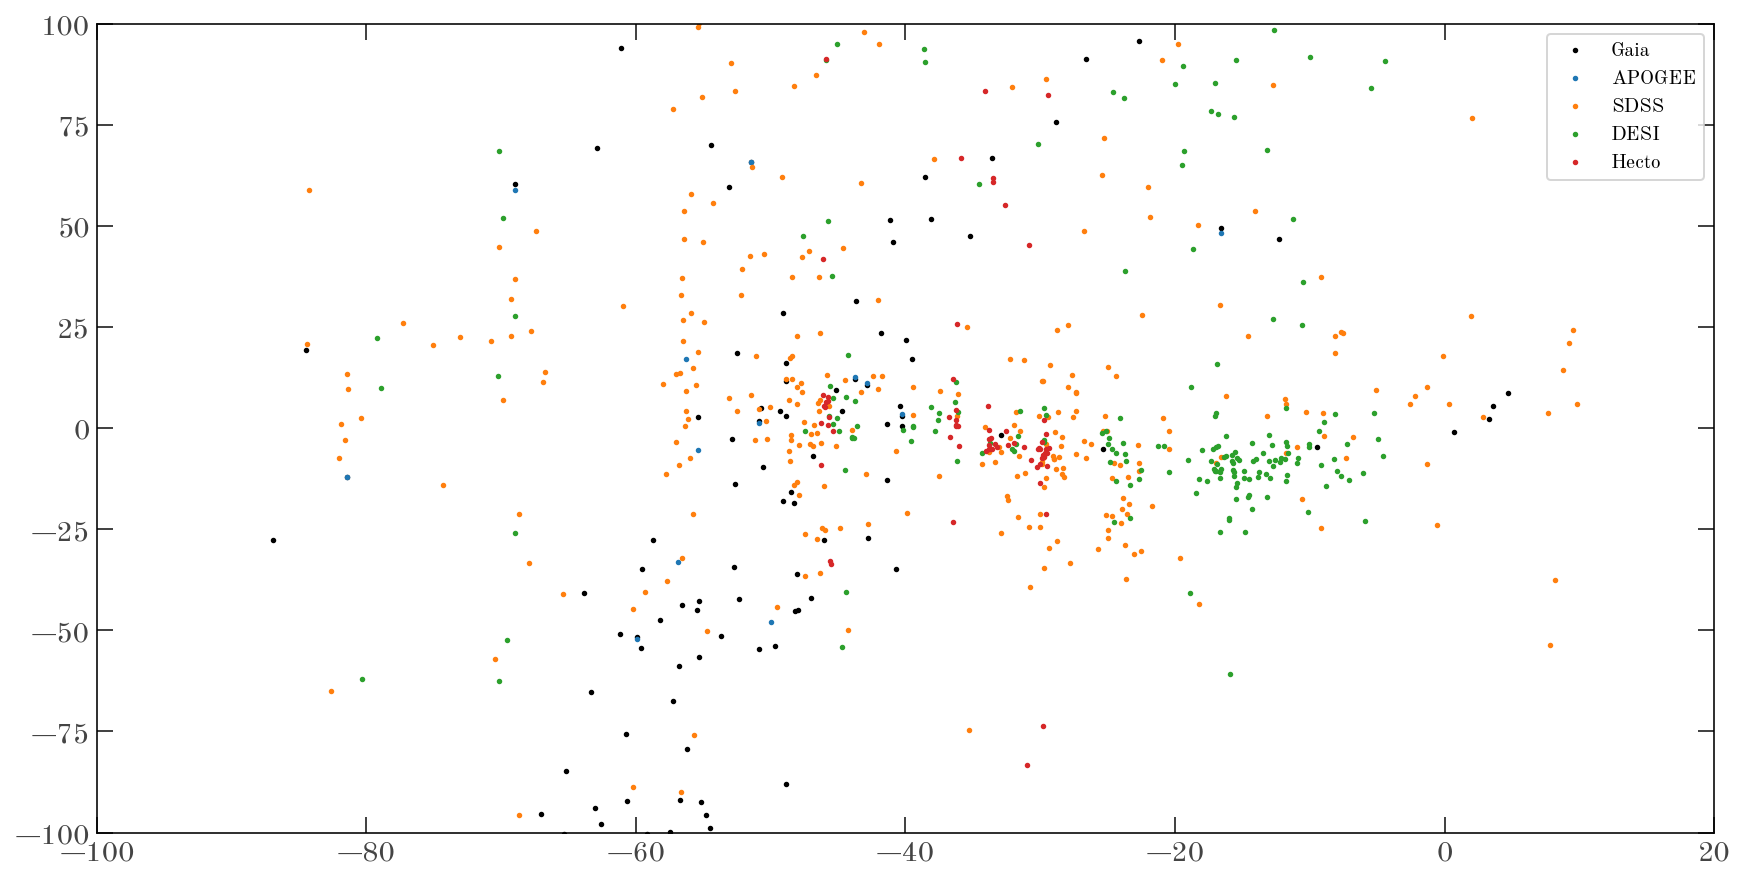

In [ ]:
_slope = (-320 - 225) / (10 - -80)
_p_thresh = 0.9

plt.figure(figsize=(12, 6))
for name, spec in all_spec.items():
    tmp_c = spec.get_skycoord(distance=10 * u.kpc)
    tmp_c = tmp_c.transform_to(gc.GD1Koposov10())

    new_y = tmp_c.radial_velocity.to_value(u.km / u.s)
    new_y -= _slope * (tmp_c.phi1.degree - 10) - 320

    if name == "SDSS":
        new_y += 7.7

    plt.scatter(
        tmp_c.phi1.degree[spec.memb_prob > _p_thresh],
        new_y[spec.memb_prob > _p_thresh],
        s=3,
        label=name,
    )

plt.xlim(-100, 20)
plt.ylim(-100, 100)
plt.legend()

In [22]:
all_spec.keys()

dict_keys(['Gaia', 'APOGEE', 'SDSS', 'DESI', 'Hecto'])

In [109]:
M = np.zeros((len(all_spec), len(all_spec)), dtype=int)
for i, spec1 in enumerate(all_spec.values()):
    for j, spec2 in enumerate(all_spec.values()):
        M[i, j] = np.isin(spec1.source_id, spec2.source_id).sum()

M

array([[16610,   904,    62,    24,    23],
       [  904,  1043,    32,     6,     0],
       [   62,    32, 13342,   611,    96],
       [   24,     6,   611,  5796,    63],
       [   23,     0,    96,    63,   688]])

---

# Prepare data arrays for modeling:

In [116]:
feh_names = {
    "APOGEE": ("FE_H", "FE_H_ERR"),
    "SDSS": ("FEH_ADOP", "FEH_ADOP_UNC"),
    "DESI": ("FEH", "FEH_ERR"),
    "Hecto": ("FeH", "std_FeH"),
}
afe_names = {
    "APOGEE": ("ALPHA_M", "ALPHA_M_ERR"),
    "SDSS": ("AFE", "AFE_UNC"),
    "DESI": ("ALPHAFE", "ALPHAFE_ERR"),
    "Hecto": ("aFe", "std_aFe"),
}

tbls = {
    name: at.QTable(
        {
            "source_id": spec.source_id,
            f"rv-{name}": spec.get_radial_velocity(),
            f"rv_err-{name}": getattr(spec, spec.radial_velocity_error_colname),
            f"feh-{name}": getattr(spec, feh_names[name][0])
            if name in feh_names
            else np.full(len(spec), np.nan),
            f"feh_err-{name}": getattr(spec, feh_names[name][1])
            if name in feh_names
            else np.full(len(spec), np.nan),
            f"alphafe-{name}": getattr(spec, afe_names[name][0])
            if name in feh_names
            else np.full(len(spec), np.nan),
            f"alphafe_err-{name}": getattr(spec, afe_names[name][1])
            if name in feh_names
            else np.full(len(spec), np.nan),
        }
    )
    for name, spec in all_spec.items()
}

In [ ]:
all_tbl = tbls["Gaia"].copy()
for name in all_spec:
    if name == "Gaia":
        continue
    all_tbl = at.join(all_tbl, tbls[name], keys="source_id", join_type="outer")

# Undo SSPP correction:
all_tbl["rv-SDSS"] += 7.0 * u.km / u.s

mask_tbl = all_tbl[[f"rv-{name}" for name in all_spec]].mask
two_surveys_mask = (
    np.logical_not(np.stack([mask_tbl[f"rv-{name}"] for name in all_spec], axis=0)).sum(
        axis=0
    )
    > 1
)

for name in all_spec:
    for x in ["rv", "feh", "alphafe"]:
        all_tbl[f"{x}-{name}"] = all_tbl[f"{x}-{name}"].filled(0.0).value
        all_tbl[f"{x}_err-{name}"] = all_tbl[f"{x}_err-{name}"].filled(np.inf).value

    all_tbl[f"feh_err-{name}"][all_tbl[f"feh-{name}"] < -5] = np.inf
    all_tbl[f"feh-{name}"][all_tbl[f"feh-{name}"] < -5] = 0.0

    all_tbl[f"alphafe_err-{name}"][all_tbl[f"alphafe-{name}"] < -5] = np.inf
    all_tbl[f"alphafe-{name}"][all_tbl[f"alphafe-{name}"] < -5] = 0.0

vals = np.array([all_tbl[f"rv-{name}"] for name in all_spec])
ivars = 1 / np.array([all_tbl[f"rv_err-{name}"] ** 2 for name in all_spec])

all_tbl["combined_rv"] = np.sum(vals * ivars, axis=0) / np.sum(ivars, axis=0)
all_tbl["combined_rv_err"] = 1 / np.sqrt(np.sum(ivars, axis=0))
all_tbl["combined_rv_err_corrected"] = all_tbl["combined_rv_err"].copy()


# Now feh:
vals = np.array([all_tbl[f"feh-{name}"] for name in all_spec])
ivars = 1 / np.array([all_tbl[f"feh_err-{name}"] ** 2 for name in all_spec])
all_tbl["combined_feh"] = np.nansum(vals * ivars, axis=0) / np.nansum(ivars, axis=0)
all_tbl["combined_feh_err"] = 1 / np.sqrt(np.nansum(ivars, axis=0))

# and alpha:
vals = np.array([all_tbl[f"alphafe-{name}"] for name in all_spec])
ivars = 1 / np.array([all_tbl[f"alphafe_err-{name}"] ** 2 for name in all_spec])
all_tbl["combined_alphafe"] = np.nansum(vals * ivars, axis=0) / np.nansum(ivars, axis=0)
all_tbl["combined_alphafe_err"] = 1 / np.sqrt(np.nansum(ivars, axis=0))

/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_65594/740056905.py:40: RuntimeWarning: invalid value encountered in divide
  all_tbl["combined_feh"] = np.nansum(vals * ivars, axis=0) / np.nansum(ivars, axis=0)
/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_65594/740056905.py:41: RuntimeWarning: divide by zero encountered in divide
  all_tbl["combined_feh_err"] = 1 / np.sqrt(np.nansum(ivars, axis=0))
/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_65594/740056905.py:46: RuntimeWarning: invalid value encountered in divide
  all_tbl["combined_alphafe"] = np.nansum(vals * ivars, axis=0) / np.nansum(ivars, axis=0)
/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_65594/740056905.py:47: RuntimeWarning: divide by zero encountered in divide
  all_tbl["combined_alphafe_err"] = 1 / np.sqrt(np.nansum(ivars, axis=0))


In [136]:
for i in np.where(two_surveys_mask)[0][5:]:
    row_var = np.var(vals[vals[:, i] != 0.0, i])
    new_err = np.sqrt((row_var + all_tbl["combined_rv_err"][i] ** 2) / 2)
    # print("vals", vals[vals[:, i] != 0.0, i])
    # print("errs", 1 / np.sqrt(ivars[vals[:, i] != 0.0, i]))
    # print("combined err", all_tbl["combined_rv_err"][i])
    # print("new err", new_err)
    all_tbl["combined_rv_err_corrected"][i] = new_err

In [ ]:
for name in all_spec:
    for x in ["rv", "feh", "alphafe"]:
        all_tbl[f"{x}-{name}"][~np.isfinite(all_tbl[f"{x}_err-{name}"])] = np.nan

all_tbl

source_id,rv-Gaia,rv_err-Gaia,feh-Gaia,feh_err-Gaia,alphafe-Gaia,alphafe_err-Gaia,rv-APOGEE,rv_err-APOGEE,feh-APOGEE,feh_err-APOGEE,alphafe-APOGEE,alphafe_err-APOGEE,rv-SDSS,rv_err-SDSS,feh-SDSS,feh_err-SDSS,alphafe-SDSS,alphafe_err-SDSS,rv-DESI,rv_err-DESI,feh-DESI,feh_err-DESI,alphafe-DESI,alphafe_err-DESI,rv-Hecto,rv_err-Hecto,feh-Hecto,feh_err-Hecto,alphafe-Hecto,alphafe_err-Hecto,combined_rv,combined_rv_err,combined_rv_err_corrected,combined_feh,combined_feh_err,combined_alphafe,combined_alphafe_err
int64,float32,float32,float64,float64,float64,float64,float32,float32,float32,float32,float32,float32,float64,float64,float32,float32,float32,float32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
576768516776162048,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,-22.103519158812983,1.0989220855393127,-0.9866350314353496,0.03213688623995357,0.21478856016488423,0.0014285571723426822,nan,inf,nan,inf,nan,inf,-22.103519158812983,1.0989220855393127,1.0989220855393127,-0.9866350314353496,0.03213688623995357,0.21478856016488423,0.0014285571723426822
576777278509416576,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,235.7589632707484,1.6013953873446596,-1.6922334597271358,0.03799183139258541,0.4369883221062175,0.0013335926615639082,nan,inf,nan,inf,nan,inf,235.7589632707484,1.6013953873446596,1.6013953873446596,-1.6922334597271356,0.03799183139258541,0.4369883221062175,0.0013335926615639082
576799474900393216,20.946503,4.516443,nan,nan,nan,nan,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,20.946502685546875,4.516442670347012,4.516442670347012,nan,inf,nan,inf
576800230814629504,-14.7211895,1.5757203,nan,nan,nan,nan,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,-14.721189498901367,1.5757202862893465,1.5757202862893465,nan,inf,nan,inf
576802425542427008,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,15.322141791743556,2.535474001470399,-1.4484722680098234,0.059629267769332764,0.5180495919449881,0.0013463466048162687,nan,inf,nan,inf,nan,inf,15.322141791743556,2.535474001470399,2.535474001470399,-1.4484722680098234,0.05962926776933276,0.5180495919449881,0.0013463466048162687
576803391910541184,24.91751,5.80867,nan,nan,nan,nan,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,24.917509078979492,5.808669930569707,5.808669930569707,nan,inf,nan,inf
576822667723825792,34.630524,1.1271495,nan,nan,nan,nan,28.969725,0.032250915,-0.011946,0.009365322,0.041786,0.007053847,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,28.974355320346348,0.03223772164450218,0.03223772164450218,-0.011946000158786774,0.00936532224202728,0.04178600013256073,0.007053846907744312
576825553941693952,1.0714833,1.4505064,nan,nan,nan,nan,0.58206797,0.045683626,-0.29602,0.011146032,0.269055,0.00863588,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,0.5825529520122402,0.04566098628272854,0.04566098628272854,-0.2960200011730194,0.01114603233331511,0.26905500888824463,0.008635880227410837
576849846276704256,-12.882441,3.8783042,nan,nan,nan,nan,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,nan,inf,-12.882440567016602,3.8783042110130577,3.8783042110130577,nan,inf,nan,inf


In [130]:
# all_tbl[two_surveys_mask].pprint(max_lines=1000, max_width=10000)

In [140]:
all_tbl.write("../data/combined-spec-rv-data.fits", overwrite=True)

In [150]:
shit = at.join(all_tbl, members.data)
shit = shit[shit["memb_prob"] > 0.75]
len(shit)

1317

In [ ]:
# all_unq_source_id = np.unique(np.concatenate([s.source_id for s in all_spec]))
# len(all_unq_source_id)

1599

In [ ]:
# all_rv = np.zeros((len(all_unq_source_id), len(all_spec)))
# all_rv_err = np.full((len(all_unq_source_id), len(all_spec)), np.inf)
# all_phi1 = np.full(all_rv.shape[0], np.nan) * u.deg
# all_mem_prob = np.full(all_rv.shape[0], np.nan)
# for i, spec in enumerate(all_spec):
#     spec = spec[np.argsort(spec.source_id)]
#     mask = np.where(np.isin(all_unq_source_id, spec.source_id))[0]
#     assert np.all(spec.source_id == all_unq_source_id[mask])

#     all_rv[mask, i] = spec.get_radial_velocity().to_value(u.km / u.s)
#     all_rv_err[mask, i] = getattr(spec, spec.radial_velocity_error_colname).to_value(
#         u.km / u.s
#     )

#     _c = spec.get_skycoord(distance=False)
#     all_phi1[mask] = _c.transform_to(gc.GD1Koposov10()).phi1
#     all_mem_prob[mask] = spec.memb_prob

In [ ]:
# all_data = at.QTable(
#     {
#         "source_id": all_unq_source_id,
#         "phi1": all_phi1,
#         "rv": all_rv * u.km / u.s,
#         "rv_err": all_rv_err * u.km / u.s,
#         "memb_prob": all_mem_prob,
#     },
#     meta={"surveys": names},
# )
# all_data.write("../data/combined-spec-rv-data.fits", overwrite=True)

# Cross-calibrate velocities to Gaia:

Note: I tried building a model to do the calibration, but simpler to just shift the SDSS velocities. So we don't use anything below here!

In [21]:
tbls = {
    name: at.QTable(
        {
            "source_id": spec.source_id,
            f"rv-{name}": spec.get_radial_velocity(),
            f"rv_err-{name}": getattr(spec, spec.radial_velocity_error_colname),
        }
    )
    for name, spec in all_spec.items()
}

In [22]:
running_tbl = tbls["Gaia"].copy()
for name in all_spec:
    if name == "Gaia":
        continue
    running_tbl = at.join(running_tbl, tbls[name], keys="source_id", join_type="outer")

In [23]:
mask_tbl = running_tbl[[f"rv-{name}" for name in all_spec]].mask
two_surveys_mask = (
    np.logical_not(np.stack([mask_tbl[f"rv-{name}"] for name in all_spec], axis=0)).sum(
        axis=0
    )
    > 1
)
two_surveys_mask.sum()

np.int64(1763)

In [24]:
running_tbl[two_surveys_mask].pprint(max_lines=100, max_width=1000)

     source_id            rv-Gaia            rv_err-Gaia          rv-APOGEE         rv_err-APOGEE           rv-SDSS          rv_err-SDSS           rv-DESI           rv_err-DESI          rv-Hecto        rv_err-Hecto  
                           km / s               km / s              km / s              km / s               km / s             km / s              km / s              km / s             km / s            km / s     
------------------- -------------------- ------------------- ------------------- -------------------- ------------------- ------------------ ------------------- ------------------- ----------------- -----------------
 576822667723825792   34.630523681640625  1.1271494626998901  28.969724655151367 0.032250914722681046                 ———                ———                 ———                 ———               ———               ———
 576825553941693952   1.0714832544326782  1.4505064487457275  0.5820679664611816  0.04568362608551979                 ———           

In [25]:
fill_rv = 0.0
fill_err = 1e4

final_data_tbl = running_tbl[two_surveys_mask]
mcmc_data = {
    "gaia_rv": final_data_tbl["rv-Gaia"].value.filled(fill_rv),
    "gaia_rv_err": final_data_tbl["rv_err-Gaia"].value.filled(fill_err),
    "other_rv": np.stack(
        [
            final_data_tbl[f"rv-{name}"].value.filled(fill_rv)
            for name in all_spec
            if name != "Gaia"
        ],
        axis=1,
    ),
    "other_rv_err": np.stack(
        [
            final_data_tbl[f"rv_err-{name}"].value.filled(fill_err)
            for name in all_spec
            if name != "Gaia"
        ],
        axis=1,
    ),
}
mcmc_data = {k: v.astype(float) for k, v in mcmc_data.items()}
mcmc_data

{'gaia_rv': array([ 34.63052368,   1.07148325, 111.13787842, ...,  25.70804596,
        337.50250244,  32.32844925]),
 'gaia_rv_err': array([1.12714946, 1.45050645, 0.32650179, ..., 0.61404687, 2.52128077,
        0.14929283]),
 'other_rv': array([[ 28.96972466,   0.        ,   0.        ,   0.        ],
        [  0.58206797,   0.        ,   0.        ,   0.        ],
        [111.09389496,   0.        ,   0.        ,   0.        ],
        ...,
        [ 25.86362839,   0.        ,   0.        ,   0.        ],
        [336.51913452,   0.        ,   0.        ,   0.        ],
        [ 32.50934982,   0.        ,   0.        ,   0.        ]]),
 'other_rv_err': array([[3.22509147e-02, 1.00000000e+04, 1.00000000e+04, 1.00000000e+04],
        [4.56836261e-02, 1.00000000e+04, 1.00000000e+04, 1.00000000e+04],
        [3.03475708e-02, 1.00000000e+04, 1.00000000e+04, 1.00000000e+04],
        ...,
        [2.72891410e-02, 1.00000000e+04, 1.00000000e+04, 1.00000000e+04],
        [5.36386520e-02,

APOGEE 0.11196128 0.11642218
SDSS 1.2785501785804452 -1.059378129972247
DESI 2.389239945474736 2.070045525532618
Hecto -14.03298735155615 -2.253872831504033


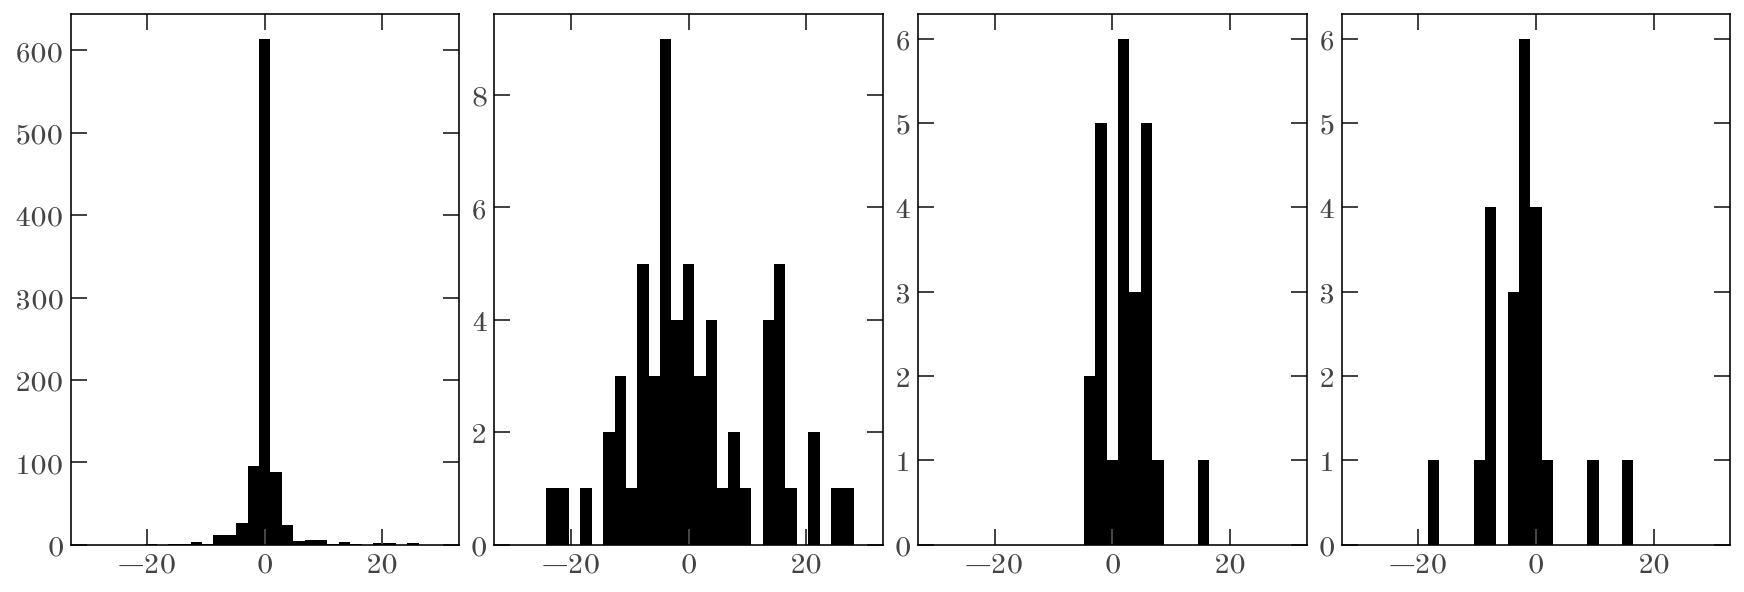

In [41]:
fig, axes = plt.subplots(1, len(all_spec) - 1, figsize=(12, 4), sharex=True)

i = 0
for name in all_spec:
    if name == "Gaia":
        continue

    drv = final_data_tbl[f"rv-{name}"].filled(np.nan) - final_data_tbl[
        "rv-Gaia"
    ].filled(np.nan)
    axes[i].hist(drv.value, bins=np.linspace(-30, 30, 32))
    i += 1

    print(name, np.nanmean(drv.value), np.nanmedian(drv.value))

In [ ]:
# def rv_calibrate_model(gaia_rv, gaia_rv_err, other_rv, other_rv_err):
#     n_surveys = other_rv.shape[1]
#     offsets = numpyro.sample("offsets", dist.Normal(0, 50), sample_shape=(n_surveys,))
#     # Qs = numpyro.sample("Qs", dist.Beta(5.0, 1.0), sample_shape=(n_surveys,))

#     # with numpyro.plate("data", len(gaia_rv)):
#     true_rv = numpyro.sample(
#         "true_rv", dist.Normal(0, 300), sample_shape=(len(gaia_rv),)
#     )
#     # true_rv_lns = numpyro.sample(
#     #     "true_rv_lns", dist.Uniform(-5, 3), sample_shape=(len(gaia_rv),)
#     # )
#     # true_rv_s = numpyro.deterministic("true_rv_s", jnp.exp(true_rv_lns))
#     true_rv_s = numpyro.sample(
#         "true_rv_s", dist.HalfNormal(0.5), sample_shape=(len(gaia_rv),)
#     )
#     numpyro.sample("obs-gaia", dist.Normal(true_rv, gaia_rv_err), obs=gaia_rv)

#     with numpyro.plate("data", len(other_rv)):
#         for i in range(n_surveys):
#             numpyro.sample(
#                 f"obs-{i}",
#                 dist.Normal(true_rv, jnp.sqrt(other_rv_err[:, i] ** 2 + true_rv_s**2)),
#                 obs=other_rv[:, i] + offsets[i],
#             )

#         # mix = dist.Categorical(probs=jnp.array([Qs[i], 1.0 - Qs[i]]))
#         # numpyro.sample(
#         #     f"obs-{i}",
#         #     dist.MixtureGeneral(  # TODO: make 100 (sigmav) a parameter?
#         #         mix,
#         #         [
#         #             dist.Normal(true_rv, other_rv_err[:, i]),
#         #             dist.Normal(true_rv, jnp.sqrt(100.0**2 + other_rv_err[:, i] ** 2)),
#         #         ],
#         #     ),
#         #     obs=other_rv[:, i] + offsets[i],
#         # )


def rv_calibrate_model(gaia_rv, gaia_rv_err, other_rv, other_rv_err):
    n_data, n_surveys = other_rv.shape
    offsets = numpyro.sample("offsets", dist.Normal(0, 50), sample_shape=(n_surveys,))

    true_rv = numpyro.sample("true_rv", dist.Normal(0, 300), sample_shape=(n_data,))

    Qs = numpyro.sample("Qs", dist.Beta(4.0, 1.0), sample_shape=(n_data,))
    binary_s = numpyro.sample("binary_s", dist.HalfNormal(50.0))

    numpyro.sample("obs-gaia", dist.Normal(true_rv, gaia_rv_err), obs=gaia_rv)

    with numpyro.plate("data", n_data):
        for i in range(n_surveys):
            mix = dist.Categorical(probs=jnp.array([Qs, 1.0 - Qs]).T)
            numpyro.sample(
                f"obs-{i}",
                dist.MixtureGeneral(
                    mix,
                    [
                        dist.Normal(true_rv, other_rv_err[:, i]),
                        dist.Normal(
                            true_rv, jnp.sqrt(binary_s**2 + other_rv_err[:, i] ** 2)
                        ),
                    ],
                ),
                obs=other_rv[:, i] + offsets[i],
            )

### Simulate some data and test

In [438]:
n_sim = 1000

rng = np.random.default_rng(123)
sim_true_rv = rng.normal(55.4, 40.0, size=n_sim)

_gaia_rv_err = rng.uniform(0.1, 1.0, size=n_sim)
_gaia_rv = rng.normal(sim_true_rv, _gaia_rv_err)
_other_rv = np.zeros((n_sim, 2))
_other_rv_err = np.full((n_sim, 2), 1e4)

# "binaries":
bin_mask = rng.uniform(size=n_sim) < 0.15
bin_std = 10 ** rng.uniform(-1, 2.0, size=n_sim)

# Survey 1
_tmp_idx = rng.choice(n_sim, size=128, replace=False)
mask = np.zeros(n_sim, dtype=bool)
mask[_tmp_idx] = True

_other_rv_err[mask, 0] = rng.uniform(0.1, 1.0, size=mask.sum())
_other_rv[mask, 0] = rng.normal(sim_true_rv[mask] - 27.7, _other_rv_err[mask, 0])
# binaries
_other_rv[mask & bin_mask, 0] = rng.normal(
    _other_rv[mask & bin_mask, 0], bin_std[mask & bin_mask]
)

# Survey 2
_tmp_idx = rng.choice(n_sim, size=128, replace=False)
mask = np.zeros(n_sim, dtype=bool)
mask[_tmp_idx] = True

_other_rv_err[mask, 1] = rng.uniform(1.0, 4.0, size=mask.sum())
_other_rv[mask, 1] = rng.normal(sim_true_rv[mask] + 14.0, _other_rv_err[mask, 1])

# binaries
_other_rv[mask & bin_mask, 1] = rng.normal(
    _other_rv[mask & bin_mask, 1], bin_std[mask & bin_mask]
)

# _gaia_rv[np.all(_other_rv != 0., axis=1)] = 0.
# _gaia_rv_err[np.all(_other_rv != 0., axis=1)] = 1e4

sim_mcmc_data = {
    "gaia_rv": _gaia_rv,
    "gaia_rv_err": _gaia_rv_err,
    "other_rv": _other_rv,
    "other_rv_err": _other_rv_err,
}

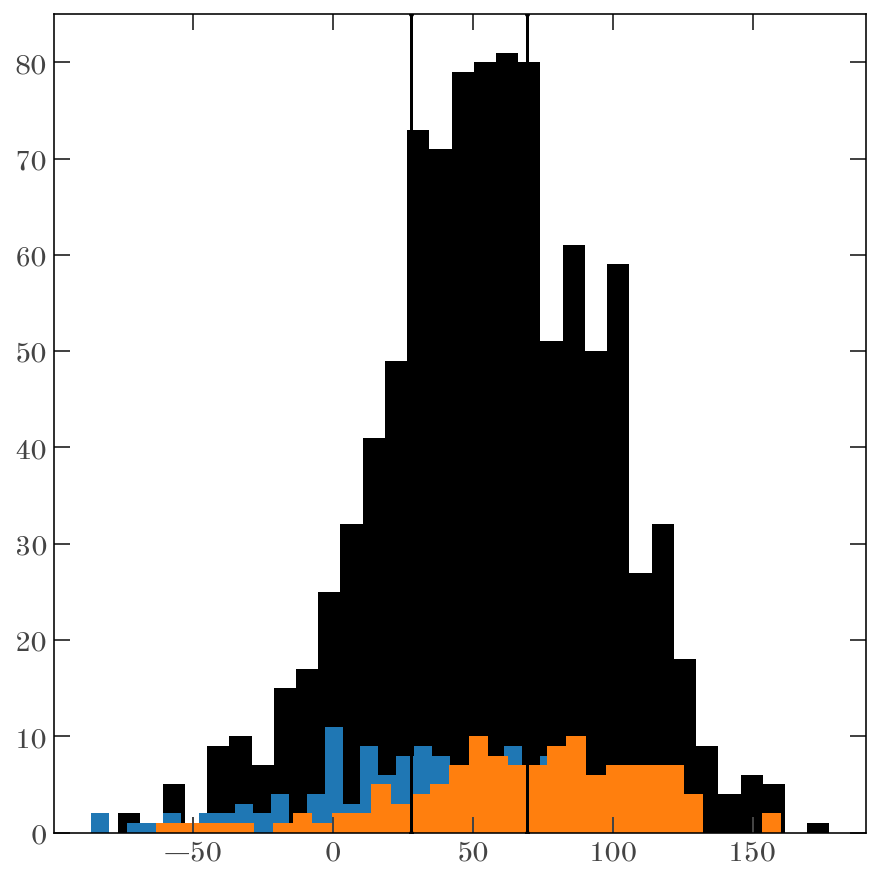

In [439]:
plt.hist(sim_mcmc_data["gaia_rv"], bins=32)
plt.hist(sim_mcmc_data["other_rv"][sim_mcmc_data["other_rv"][:, 0] != 0.0, 0], bins=32)
plt.axvline(55.4 - 27.7)
plt.hist(sim_mcmc_data["other_rv"][sim_mcmc_data["other_rv"][:, 1] != 0.0, 1], bins=32)
plt.axvline(55.4 + 14.0)

In [440]:
kernel = infer.NUTS(rv_calibrate_model)
mcmc = infer.MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=4)
mcmc.run(
    jax.random.PRNGKey(42),
    **sim_mcmc_data,
);

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

  0%|          | 0/6000 [00:00<?, ?it/s]

In [441]:
mcmc.get_samples()["offsets"].mean(axis=0)

Array([ 27.65897353, -14.23030405], dtype=float64)

In [442]:
mcmc.get_samples()["offsets"].std(axis=0)

Array([0.05387721, 0.20332859], dtype=float64)

In [443]:
az.summary(mcmc, var_names=["offsets"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
offsets[0],27.659,0.054,27.557,27.758,0.000,0.000,12817.0,12777.0,1.0
offsets[1],-14.230,0.203,-14.617,-13.855,0.001,0.001,34707.0,12967.0,1.0


In [444]:
mcmc.get_samples()["binary_s"].mean(axis=0)

Array(20.08993843, dtype=float64)

In [445]:
sim_true_rv_pred = mcmc.get_samples()["true_rv"].mean(axis=0)
sim_true_rv_err_pred = mcmc.get_samples()["true_rv"].std(axis=0)

<ErrorbarContainer object of 3 artists>

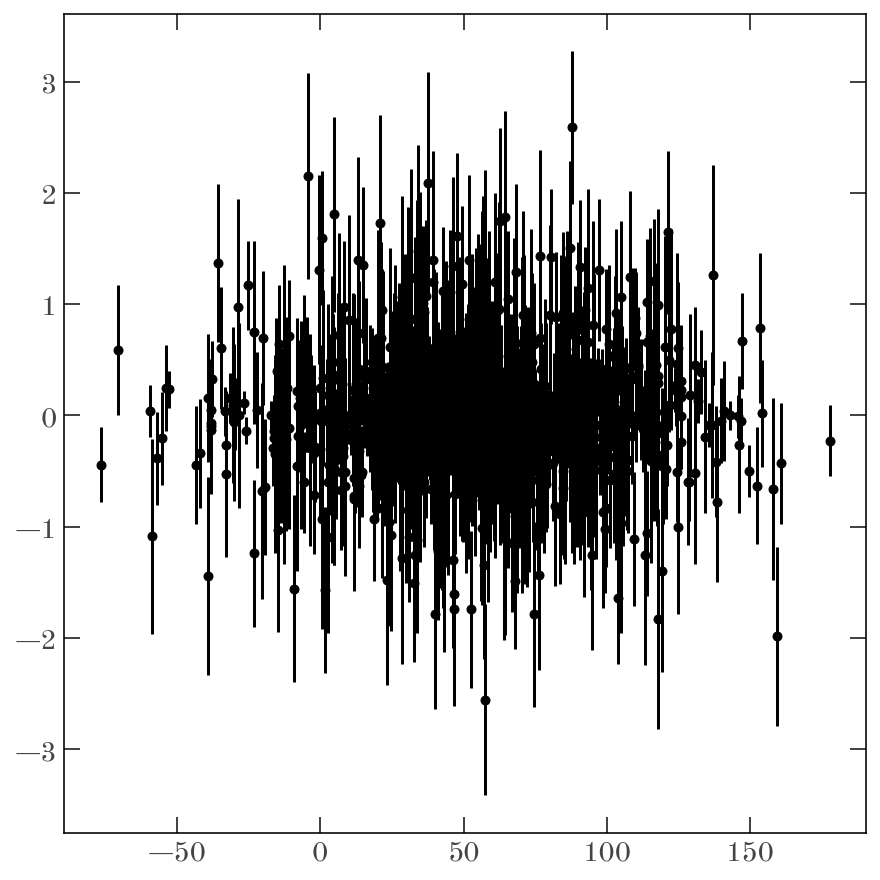

In [447]:
plt.errorbar(sim_true_rv, sim_true_rv_pred - sim_true_rv, sim_true_rv_err_pred, fmt="o")

### Run with real data

In [448]:
mcmc_data["gaia_rv"].shape

(1763,)

In [449]:
kernel = infer.NUTS(rv_calibrate_model)
mcmc = infer.MCMC(kernel, num_warmup=1000, num_samples=1000, num_chains=4)
mcmc.run(jax.random.PRNGKey(42), **mcmc_data);

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [450]:
all_spec.keys()

dict_keys(['Gaia', 'APOGEE', 'SDSS', 'DESI', 'Hecto'])

In [451]:
mcmc.get_samples()["offsets"].mean(axis=0)

Array([-0.17093744, -0.70586297, -1.56420569,  0.81235652], dtype=float64)

In [452]:
mcmc.get_samples()["offsets"].std(axis=0)

Array([0.01008189, 0.29136101, 0.11313239, 0.13748334], dtype=float64)

In [453]:
az.summary(mcmc, var_names=["offsets"])

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
offsets[0],-0.171,0.010,-0.189,-0.156,0.005,0.003,5.0,15.0,2.26
offsets[1],-0.706,0.291,-1.256,-0.164,0.033,0.023,79.0,121.0,1.04
offsets[2],-1.564,0.113,-1.784,-1.381,0.035,0.025,10.0,36.0,1.31
offsets[3],0.812,0.138,0.590,1.083,0.045,0.033,9.0,25.0,1.36


APOGEE 0.11196128 0.11642218
SDSS 1.2785501785804452 -1.059378129972247
DESI 2.389239945474736 2.070045525532618
Hecto -14.03298735155615 -2.253872831504033


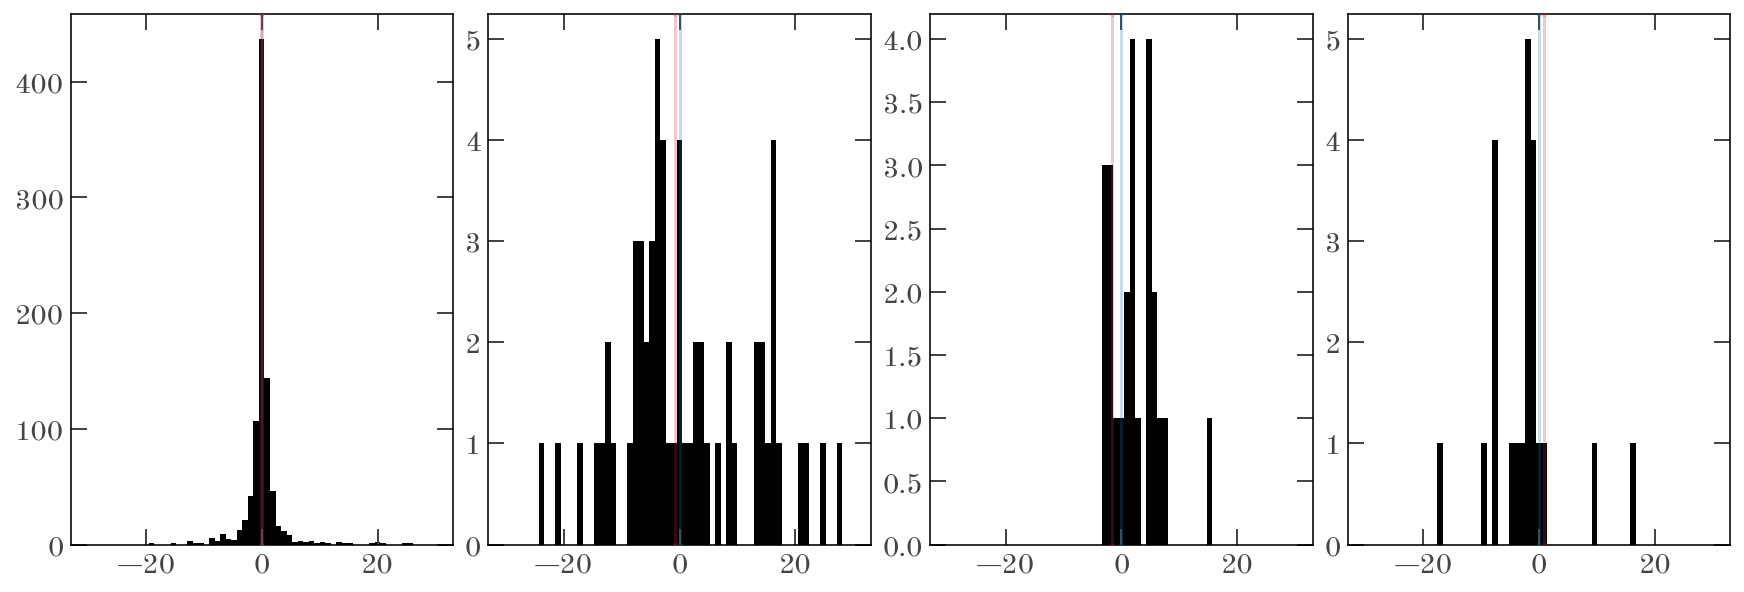

In [454]:
mean_offsets = mcmc.get_samples()["offsets"].mean(axis=0)

fig, axes = plt.subplots(1, len(all_spec) - 1, figsize=(12, 4), sharex=True)

i = 0
for name in all_spec:
    if name == "Gaia":
        continue

    drv = final_data_tbl[f"rv-{name}"].filled(np.nan) - final_data_tbl[
        "rv-Gaia"
    ].filled(np.nan)
    axes[i].hist(drv.value, bins=np.linspace(-30, 30, 64))
    axes[i].axvline(0.0, color="tab:blue", zorder=10, alpha=0.25)
    axes[i].axvline(mean_offsets[i], color="tab:red", zorder=10, alpha=0.25)
    i += 1

    print(name, np.nanmean(drv.value), np.nanmedian(drv.value))

In [455]:
true_rv_pred = mcmc.get_samples()["true_rv"].mean(axis=0)
true_rv_err_pred = mcmc.get_samples()["true_rv"].std(axis=0)
# true_rv_s_pred = mcmc.get_samples()["true_rv_s"].mean(axis=0)

(-30.0, 30.0)

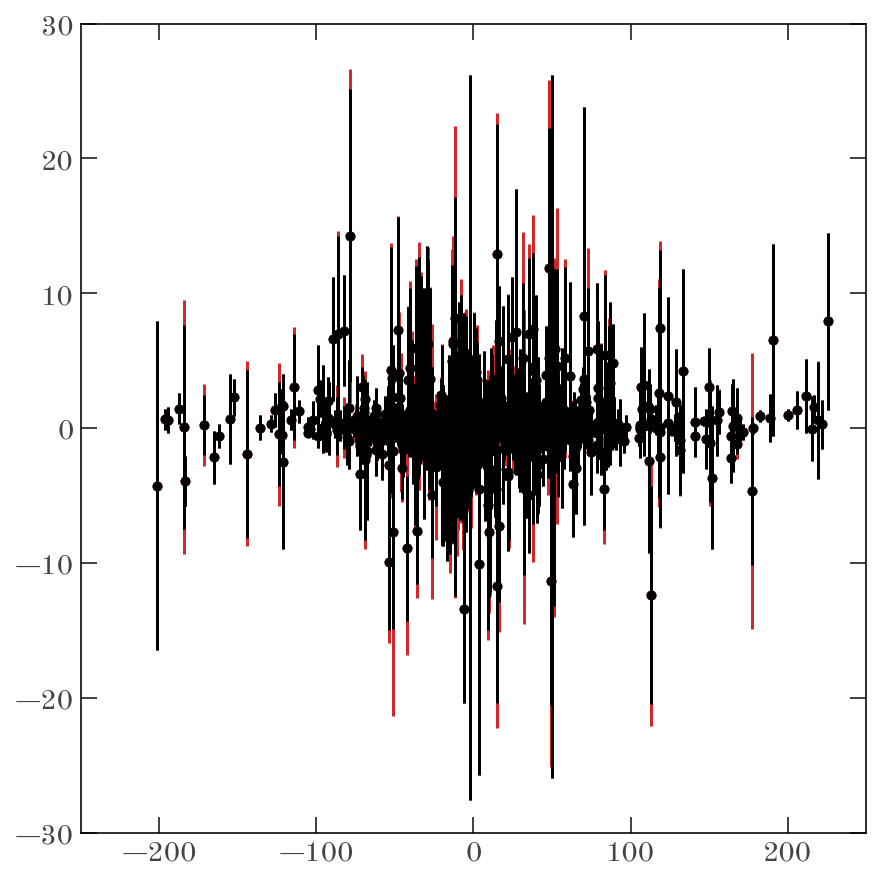

In [ ]:
_mask = mcmc_data["gaia_rv"] != 0
plt.errorbar(
    true_rv_pred[_mask],
    (mcmc_data["gaia_rv"] - true_rv_pred)[_mask],
    mcmc_data["gaia_rv_err"][_mask],
    marker="o",
    ls="none",
)
plt.errorbar(
    true_rv_pred[_mask],
    (mcmc_data["gaia_rv"] - true_rv_pred)[_mask],
    np.sqrt(mcmc_data["gaia_rv_err"] ** 2 + true_rv_err_pred**2)[_mask],
    marker="o",
    ls="none",
    zorder=-10,
    color="tab:red",
)
plt.xlim(-250, 250)
plt.ylim(-30, 30)

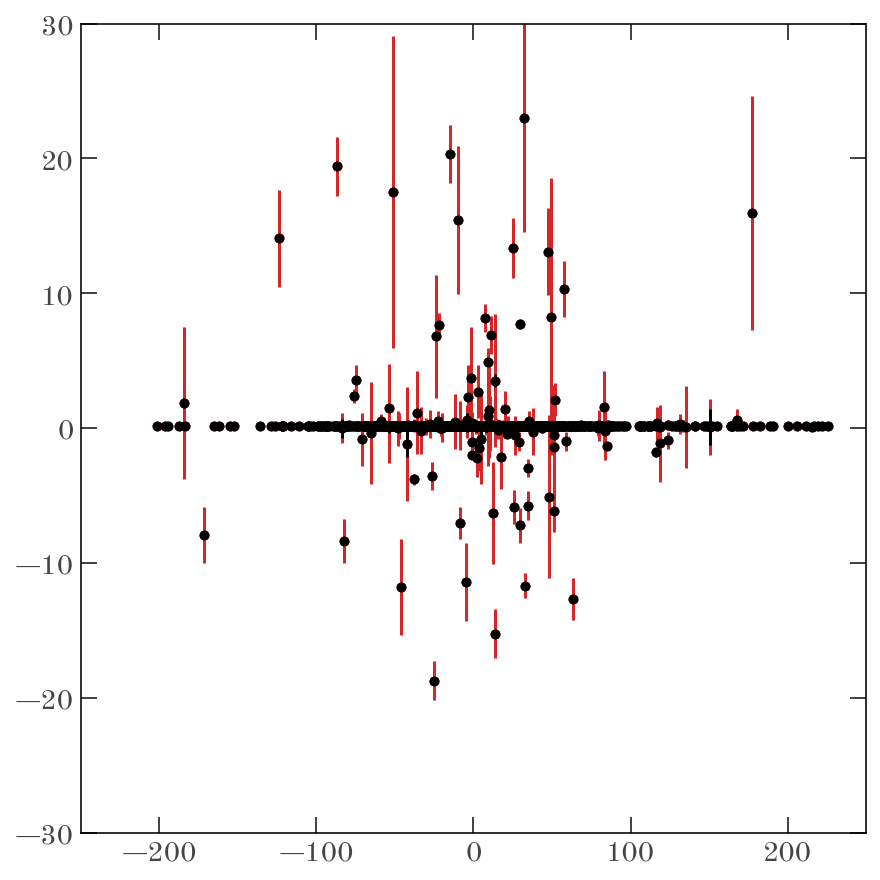

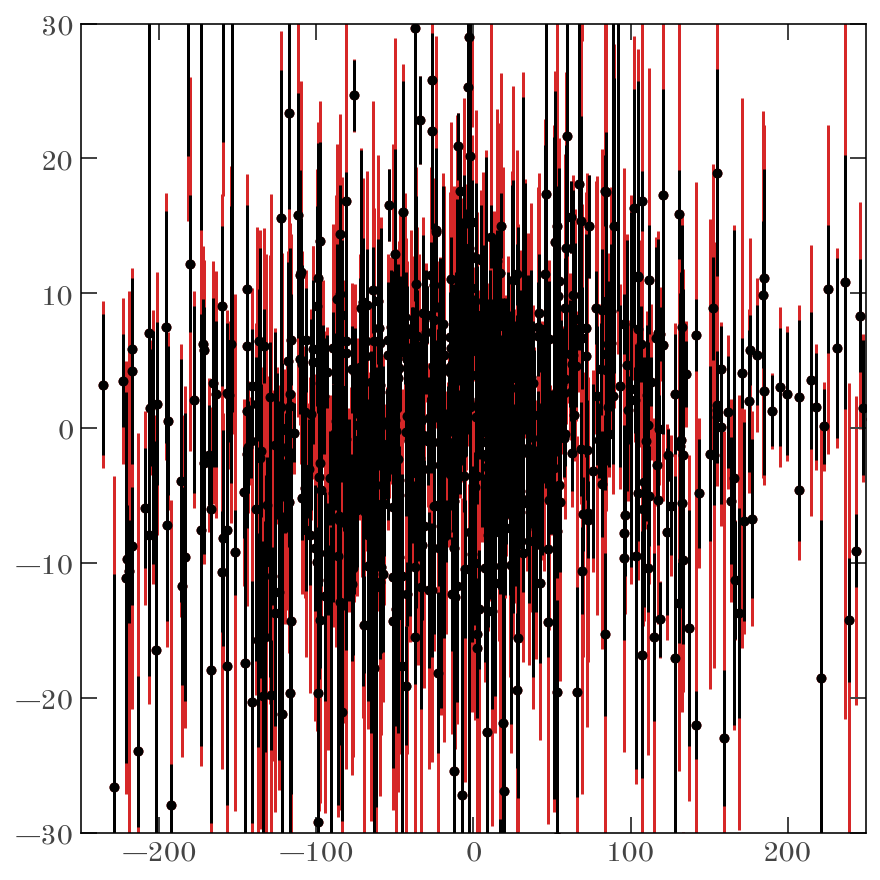

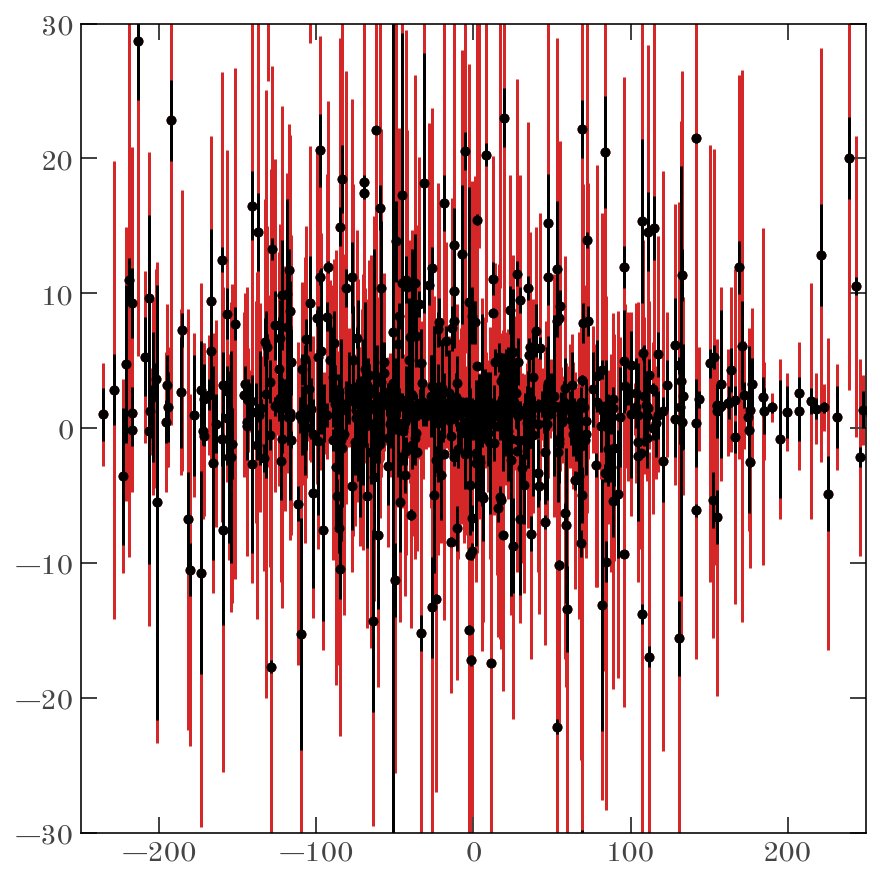

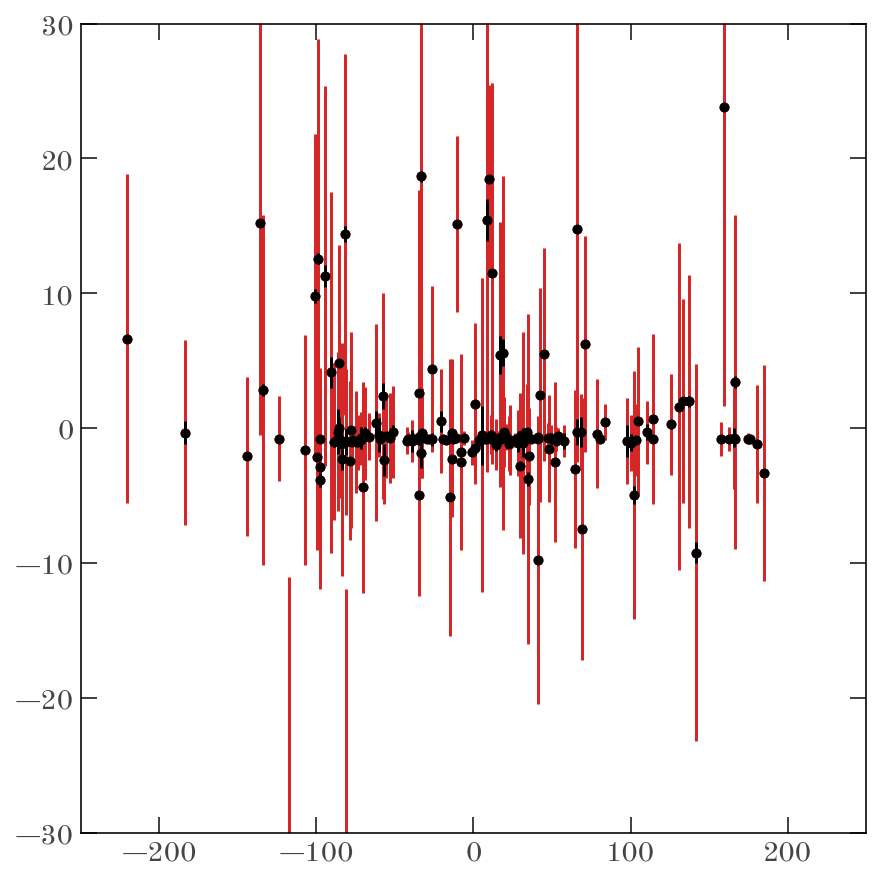

In [ ]:
for i in range(mcmc_data["other_rv"].shape[1]):
    plt.figure()
    _mask = mcmc_data["other_rv"][:, i] != 0
    plt.errorbar(
        true_rv_pred[_mask],
        (mcmc_data["other_rv"][:, i] - true_rv_pred)[_mask],
        mcmc_data["other_rv_err"][_mask, i],
        marker="o",
        ls="none",
    )
    plt.errorbar(
        true_rv_pred[_mask],
        (mcmc_data["other_rv"][:, i] - true_rv_pred)[_mask],
        np.sqrt(mcmc_data["other_rv_err"][:, i] ** 2 + true_rv_err_pred**2)[_mask],
        marker="o",
        ls="none",
        zorder=-10,
        color="tab:red",
    )
    plt.xlim(-250, 250)
    plt.ylim(-30, 30)

In [459]:
two_surveys_mask.shape, prob_mask_75.shape

((35687,), (521925,))

In [434]:
true_rv_pred.size, spec.memb_prob.size

(1763, 688)

In [ ]:
all_spec = [gaia_g, apogee_g, sdss_g, desi_g, hecto_g]
all_spec = [s[np.isfinite(s.get_radial_velocity())] for s in all_spec]
all_spec = [s[np.unique(s.source_id, return_index=True)[1]] for s in all_spec]
names = ["Gaia", "APOGEE", "SDSS", "DESI", "Hecto"]
all_spec = {k: s for k, s in zip(names, all_spec)}

for name, spec in all_spec.items():
    tmp_c = spec.get_skycoord(distance=10 * u.kpc)
    tmp_c = tmp_c.transform_to(gc.GD1Koposov10())
    # tmp_c = gc.reflex_correct(tmp_c)

    plt.figure(figsize=(7, 4))
    plt.title(name)
    plt.scatter(
        tmp_c.phi1.degree,
        tmp_c.radial_velocity.to_value(u.km / u.s),
        c=spec.memb_prob,
        s=2,
        cmap="magma_r",
        vmin=0.9,
        vmax=1.0,
    )
    plt.xlim(-100, 20)
    plt.ylim(-400, 400)
    plt.colorbar()

# plt.legend()